1. Business scenario



In [1]:
#  Imagine that we work as a data Analyst an e-commerce company.
#  The business receives customer. product, order and payments files diffrent systems.
#  Every day, operations team, combines these files manually to prepare sales reorts.
#  this process is time consuming and creates errors.
#  our responsibility is to build a reusable python workflow that
#  1.Reads multiple business files.
#  2.Validates the data.
#  3.Cleans inconsistent records.
#  4.Combines business metrics.
#  5.Products reports.
#  6.Products reports.
#  7.Saves the final output files.

# This is similar to a practical data- processing workflow used in analytics and data engineering teams




2.Tools and technologics


In [2]:
# from typing import ClassVar
# Technology                                Purpose
# Python 3                          Programing language
# Pandas                            Data manipulation
# Numpy                             Numerical operations
# Matplotlib                        Visualisation
# Seaborn                           Statistical charts
# Jupiter or collab                 development envurnoment
# CSV                               Input and output format
# GitHub                            Version control

3.Project folder structure

In [3]:
# Python e-cimmerce reporting /
# data/
     # customer.csv
     # order.csv
     # product.csv
     # payment.csv
# Outputs/
# note books/
     # ecommerce pipeline.py
# README.md
# requirments.text

4. Dataset requirments

In [4]:

# customer.csv :

# customer_id,customer_name,City
# 101,Arun, Bengaluru
# 102,Priya,Chennai
# 103,Rahul,Hydrabad
# 104,Meena, Mumbai

# products.csv :
# product_id,product_name,category,unit_price
# 201,Laptop,Electronics,55000
# 202,Mouse,Accessories,800
# 203,Keyboard,Accessories,1500
# 204,Monitor,Electronics,12000

# order.csv :
# order_id,customer_id,product_id,order_date,quantity,status
# 1001,101,201,2026-01-05,1,Completed
# 1002,102,202,2026-01-06,2,Completed
# 1003,103,203,2026-01-07,1,Completed
# 1004,104,204,2026-01-08,2,Completed

# Payment.csv :
# payment_id,order_id,payment_method,payment_status
# 5001,1001,UPI,Successful
# 5002,1002,Card,Successful
# 5003,1003,UPI,Failed
# 5004,1004,Card,Successful
# These rows only demostrating the file structure.students should use a substantially larger dataset for the completed portpolio project




5. Step 1 - Setup python

In [5]:
# Importent libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as pit
import seaborn as sns

from pathlib import Path

# pandas handles tabularbar
# Numpy supports numerical operations
# Matplotlib create charts
# Seabon creats statstcal visualisations,
# Path helps manage file paths.


print("pandas Version:",pd.__version__)
print("Numpy Version:",np.__version__)
print("E-commerce Project started Successful")

pandas Version: 2.2.3
Numpy Version: 2.4.6
E-commerce Project started Successful


6.Step 2.Load datasets

In [6]:
import pandas as pd

customers = pd.read_csv('/content/customers.csv')
orders = pd.read_csv('/content/orders.csv')
products =pd.read_csv('/content/products.csv')
payments = pd.read_csv('/content/payments.csv')

# Explination
# pd.read_csv() reads CSV file into a DataFrame.
# A DataFrame is a two_dimensional table containing rows and columns.
# The dat_path variable stores the folder location. this makes it easier to manage files without repeatedliy typing their path


7.Step 3 - Understand the datasets

In [7]:
print("customers:\n",customers.shape)
print("orders:\n",orders.shape)
print("products:\n",products.shape)
print("payments:\n",payments.shape)

# shape returns the number of rows and columns

customers:
 (40000, 4)
orders:
 (30000, 6)
products:
 (10000, 4)
payments:
 (20000, 5)


In [8]:
# display the  first five rows
print("customers first five rows:\n",customers.head())
print("first five orders:\n",orders.head())
print("first five products:\n",products.head())
print("first five payments:\n",payments.head())

customers first five rows:
    customer_id customer_name       city signup_date
0       100001   Kavya Reddy       Pune  2024-01-05
1       100002   Meena Gupta    Kolkata  2026-05-19
2       100003  Ananya Gupta  Ahmedabad  2023-02-20
3       100004     Asha Nair  Ahmedabad  2024-04-23
4       100005    Manoj Nair      Kochi  2025-11-13
first five orders:
    order_id  customer_id  product_id  order_date  quantity     status
0    300001       112908      208718  2025-03-09         1  Completed
1    300002       113022      205348  2026-09-15         4  Completed
2    300003       104495      208281  2025-06-16         2  Completed
3    300004       108487      209373  2026-06-28         1  Completed
4    300005       136261      200339  2025-08-06         5  Completed
first five products:
    product_id                product_name     category  unit_price
0      200001     Cricket Bat Model 00001       Sports    16568.44
1      200002  Vacuum Cleaner Model 00002         Home     5448.

In [9]:
# display the column names data types and non-null counts.
print("customer information:\n",customers.info())
print("orders information:\n",orders.info())
print("produsts information:\n",products.info())
print("payment information:\n",payments.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customer_id    40000 non-null  int64 
 1   customer_name  39950 non-null  object
 2   city           39900 non-null  object
 3   signup_date    40000 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.2+ MB
customer information:
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   order_id     30000 non-null  int64 
 1   customer_id  30000 non-null  int64 
 2   product_id   30000 non-null  int64 
 3   order_date   29950 non-null  object
 4   quantity     30000 non-null  int64 
 5   status       29960 non-null  object
dtypes: int64(4), object(2)
memory usage: 1.4+ MB
orders information:
 None
<class 'pandas.core.frame.DataFrame'>
RangeI

In [10]:
# this count missing values each columns
print("customers missing:\n",customers.isnull().sum())
print("orders missing values:\n",orders.isnull().sum())
print("products missing values:\n",products.isnull().sum())
print("payments missing values:\n",payments.isnull().sum())

# isnull() checks whether values are missing
#sum() counnts how many missing values
# explain that inspection must hapen before cleaning. we should uderstant the condition of the input data before deciding what to change

customers missing:
 customer_id        0
customer_name     50
city             100
signup_date        0
dtype: int64
orders missing values:
 order_id        0
customer_id     0
product_id      0
order_date     50
quantity        0
status         40
dtype: int64
products missing values:
 product_id       0
product_name     0
category        40
unit_price       0
dtype: int64
payments missing values:
 payment_id         0
order_id           0
payment_method    60
payment_status    40
payment_date       0
dtype: int64


8.step 4 clean datasets

In [11]:
# Standerdise column names
for df in [customers, orders, products, payments]:   # the loop throug each dataFrame
     df.columns = (
         df.columns       # Accesss the data column names .str.strip()
         .str .strip()    # Removes extra spacees at the begining and end.
         .str .lower()    # converts column names to lowercase
         .str .replace(" ", "_") #Replaces spaces with underscores
)




In [12]:
# remove duplicate recods
customers = customers.drop_duplicates(
    subset =["customer_id"]
)
orders = orders.drop_duplicates(
    subset =["order_id"]
)
products =products.drop_duplicates(
    subset = ["product_id"]
)
payments = payments.drop_duplicates(
    subset = ["payment_id"]
)

# drop_duplicates() :it removes duplicate records
# subset = ["order_id"] tells pandas which column to use to identify duplicates
# we can check duplicates befor removing them

print(orders.duplicated(subset = ["order_id"]).sum())
print(customers.duplicated(subset =["customer_id"]).sum())
print(products.duplicated(subset =["product_id"]).sum())
print(payments.duplicated(subset = ["payment_id"]).sum())

0
0
0
0


In [13]:
# Convert dates into datetime
orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors ="coerce"
)
# error ="coerce" converts invalid values into missing values rather than stoping the entire conversation


# display the dates after convertinf datetime
print("datetime:\n",orders["order_date"])

datetime:
 0       2025-03-09
1       2026-09-15
2       2025-06-16
3       2026-06-28
4       2025-08-06
           ...    
29995   2025-06-17
29996   2025-09-27
29997   2025-02-04
29998   2026-03-01
29999   2025-04-08
Name: order_date, Length: 29900, dtype: datetime64[ns]


In [14]:
# we can check invalide date value
invalid_dates = orders[
    orders["order_date"].isna()
]


In [15]:
# Converts numerical columns
orders["quantity"] = pd.to_numeric(
    orders["quantity"],
    errors ="coerce"
)
products["unit_price"] = pd.to_numeric(
    products["unit_price"],
    errors = "coerce"
)


In [16]:
# Check invalied quantities
invalid_quantity = orders[
    orders["quantity"].isna()
    |(orders["quantity"] <=0)

]
# display invalid quantity
print("invalid quantity:\n",invalid_quantity)
# Do not blindly replace all missing values with zero.the correct handing depends on the business meaning of the colimn


invalid quantity:
        order_id  customer_id  product_id order_date  quantity     status
275      300276       132770      206072 2026-08-16         0  Completed
711      300712       107611      201213 2025-03-15         0    Pending
812      300813       136245      200214 2026-02-13        -1  Completed
946      300947       103426      209413 2025-12-28         0  Completed
994      300995       112351      207127 2025-08-15        -1  Completed
...         ...          ...         ...        ...       ...        ...
28634    328635       106124      204964 2026-04-11         0  Completed
28796    328797       129549      204573 2025-08-22         0  Completed
29093    329094       128892      201686 2025-02-05         0  Completed
29153    329154       123594      207497 2025-11-10         0  Cancelled
29350    329351       110619      207990 2025-08-23         0  Completed

[104 rows x 6 columns]


In [17]:
# Check invalid price
invalid_price = products[
    products["unit_price"].isna()
    |(products["unit_price"]<=0)
]
# doslay invalid price
print("invalid price:\n",invalid_price)

#

invalid price:
       product_id                product_name     category  unit_price
100       200101          Camera Model 00101  Electronics        -1.0
698       200699           Shoes Model 00699      Fashion        -1.0
717       200718         Monitor Model 00718  Electronics        -1.0
1192      201193           Watch Model 01193      Fashion        -1.0
1525      201526   Children Book Model 01526        Books        -1.0
1716      201717         Printer Model 01717  Electronics        -1.0
2177      202178      Smartphone Model 02178  Electronics        -1.0
2314      202315           Jeans Model 02315      Fashion        -1.0
2676      202677        Cookbook Model 02677        Books        -1.0
2715      202716        Cookbook Model 02716        Books        -1.0
2844      202845          Laptop Model 02845  Electronics        -1.0
3258      203259   Skipping Rope Model 03259       Sports        -1.0
3887      203888          Tablet Model 03888  Electronics        -1.0
4181

9.Step 5 - Validate relationships


In [18]:
# now check the relationship between datasets
# identify orders with  missing customers
# Extracts all customer ids from customers DtaFrame
# isin() Chexke whether each order's customers id existis in the customer list
# ~ Means NOT it reverses the result

invalid_customers = orders[
    ~ orders["customer_id"].isin(
        customers["customer_id"]
    )
]
print("invalid customers:\n",invalid_customers)

invalid customers:
        order_id  customer_id  product_id order_date  quantity     status
322      300323       113651      202339 2025-05-09         1  Completed
386      300387       999999      206328 2025-11-23         2  Cancelled
425      300426       999999      207164 2025-05-25         4  Completed
544      300545       999999      207471 2025-03-11         2  Completed
1019     301020       999999      206877 2026-06-18         4  Completed
...         ...          ...         ...        ...       ...        ...
28325    328326       999999      201419 2025-05-10         5  Completed
28560    328561       126915      204560 2025-06-16         3  Cancelled
28581    328582       138808      201710 2025-04-15         3  Completed
29560    329561       999999      209357 2026-10-07         3  Completed
29668    329669       999999      206366 2026-08-25         3  Completed

[125 rows x 6 columns]


In [19]:
# identify orders with missimg products:
invalid_products = orders[
    ~orders["product_id"].isin(
        products["product_id"]
    )
]
print("invalid prodicts:\n",invalid_products)

invalid prodicts:
        order_id  customer_id  product_id order_date  quantity     status
175      300176       139006      999999 2026-07-03         2    Pending
198      300199       132464      203730 2025-03-05         1  Completed
229      300230       127326      203893 2026-02-22         1  Completed
255      300256       132174      999999 2025-01-31         5  Completed
279      300280       104042      209778 2026-03-27         3  Completed
...         ...          ...         ...        ...       ...        ...
29110    329111       125816      202336 2026-06-28         4  Completed
29232    329233       135699      201688 2025-05-15         1  Completed
29524    329525       138926      201626 2025-03-08         1  Cancelled
29788    329789       124688      999999 2025-08-17         5    Pending
29917    329918       113601      207361 2025-06-10         3  Completed

[246 rows x 6 columns]


10.Step 6 - Combine the datasets(merge)

In [20]:
# this one of the most important step in the project
# orders - what the customer ordered
# customers - who the customers is
# products - what products they  purchased and its prise
# payments - whether the order was paid for



In [21]:
# 1.Merge with customers
sales = orders.merge(
    customers,
    on="customer_id",
    how="left"

)
# merge with products
sales = sales.merge(
    products,
    on="product_id",
    how ="left"
)
# merge payments
sales = sales.merge(
    payments,
    on="order_id",
    how ="left"
)
# explian
# merge() as acombine a DataFrame using acommon key.
# how ="left":all records from the left DataFrame are retained,and matching records
    # from the right DataFrame added, if a customer is not found,customer information will br missing


11.Step 7 - Calculate business metrics

In [22]:
#1.Calculate revenue
sales["revenue"] =(
    sales["quantity"]* sales["unit_price"]
)

# filter completed orders with successful payment
completed_sales =sales[
    (sales["status"]== "Completed")
    &(sales["payment_status"]== "Successful").copy()
]

# Calculate total revenue
total_revenue = completed_sales["revenue"].sum()
print("Total revenue:",total_revenue)

Total revenue: 617896813.1299999


In [23]:
# calculate total orders
total_orders = completed_sales["order_id"].nunique()

# Display total orders
print("Total Orders:",total_orders)

# nunique() counts the number of unique values
# why not use count() : because it counts rows. if an order has multiple products or multiple payments
   # one order may appear multiple rows

Total Orders: 12321


In [24]:
# calculate Average order value
order_total =(
    completed_sales.groupby("order_id")["revenue"].sum()
)
average_order_value = order_total.mean()
print("Average order value:",average_order_value)

# we calculate order total than calculte average order
# average order value = total revenue/number of orders

Average order value: 50149.89149663175


In [25]:
# Calculate city wise revenue
city_sales =(
    completed_sales.groupby("city")["revenue"].sum()
               .sort_values(ascending =False)
)
print("City Sales:\n",city_sales)





City Sales:
 city
Hyderabad     57975279.91
Vijayapura    53752770.18
Mysuru        53063229.12
Mumbai        52124833.22
Jaipur        51853434.19
Ahmedabad     51668750.88
Chennai       51041825.13
Bengaluru     50135677.44
Kochi         49985103.25
Delhi         49814957.93
Pune          46912656.36
Kolkata       45815047.37
Name: revenue, dtype: float64


In [26]:
# Claculate product wise revenue
product_sales =(
     completed_sales.groupby("product_name")["revenue"].sum()
     .sort_values(ascending = False)
)
print("Product Revenue:\n",product_sales)

Product Revenue:
 product_name
Monitor Model 07819        2131792.74
Smartphone Model 02851     1589448.98
Monitor Model 02883        1535966.08
Laptop Model 05390         1530548.85
Laptop Model 06017         1465766.38
                              ...    
T-Shirt Model 05769          -3155.92
Yoga Mat Model 05016        -11557.81
Dumbbell Model 00214        -11851.22
Cricket Bat Model 00565     -17065.40
Headphones Model 02742     -110247.72
Name: revenue, Length: 7032, dtype: float64


12.Step 8 - Create visualisations

/tmp/ipykernel_546/2495449580.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  completed_sales["sales_month"] = (


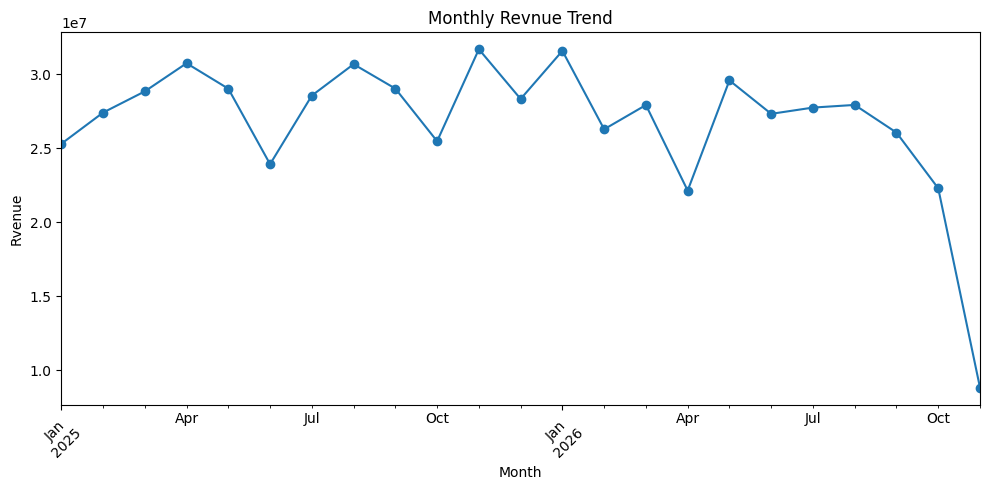

In [27]:
# calulate monthly sales:
# How many revenue did we generate each month?
# Extract the month from the order date

completed_sales["sales_month"] = (
    completed_sales["order_date"].dt.to_period("M")
)
monthly_sales =(
    completed_sales.groupby("sales_month")["revenue"].sum()
)
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)
pit.title("Monthly Revnue Trend")
pit.xlabel("Month")
pit.ylabel("Rvenue")
pit.xticks(rotation= 45)
pit.tight_layout()
pit.show()

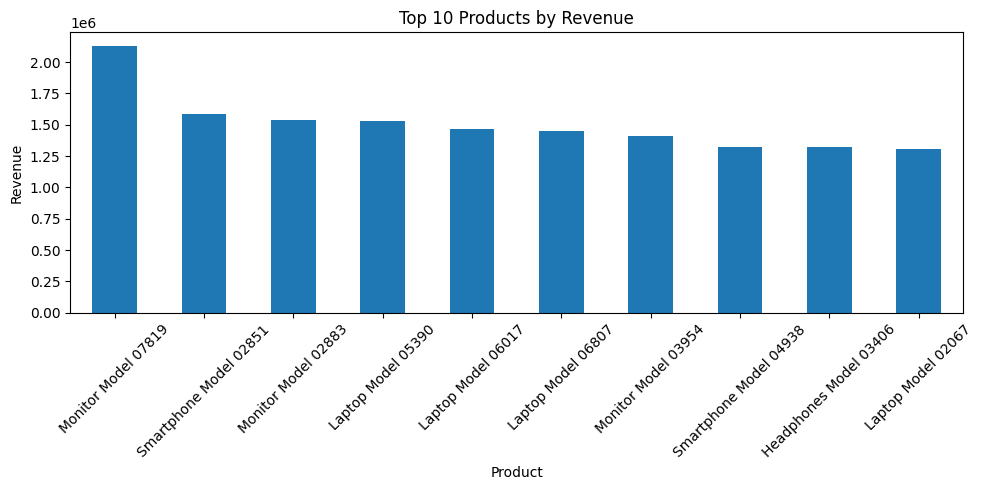

In [28]:
# Top products(chart)
top_produsts = product_sales.head(10)

top_produsts.plot(
    kind = "bar",
    figsize=(10,5)
)
pit.title("Top 10 Products by Revenue")
pit.xlabel("Product")
pit.ylabel("Revenue")
pit.xticks(rotation=45)
pit.tight_layout()
pit.show()



13.Step 9 - Export results

In [29]:
# exports results:
# After the analysis, we need to save our reports as files so the business team can use them
# 1.create output folder:
output_path = Path("outputs")

output_path.mkdir(
    parents=True,
    exist_ok=True
)
# 2.Exports cleaned sales dataset
completed_sales.to_csv(
    output_path / "cleaned_sales.csv",
    index=False
)
# index=False : prevents Pandas from adding an extra index column
# 3.Export city sales
city_sales.to_csv(
    output_path / "city_sales.csv"

)
# 4.Export products sales
product_sales.to_csv(
    output_path / "product_sales.csv"
)
# Export monthly sales
monthly_sales.to_csv(
    output_path / "monthly_sales.csv"
)
print("All files Exported Succfully!")

All files Exported Succfully!


14.Step.10 - Make the workflow reusable

In [30]:
# The next step is to operations into functions so that workflow can be executed again when new files arrive
# function: A function is a reusable block of code that performs a specific task.
# Example
def calculate_revenue(df):
    df= df.copy()
    df["revenue"] = (
        df["quantity"] * df["unit_price"]
)
    return df

def calculate_city_sales(df):
  return (
      df.groupby("city")["revenue"].sum().sort_values(ascending=False)
  )
  # Explain why function is mater
  #1.Reusability
  #2.Easier testing
  #3.less repeated code
  #4.Easier maintainance

In [31]:
from google.colab import files
files.download("outputs/cleaned_sales.csv")
files.download("outputs/city_sales.csv")
files.download("outputs/product_sales.csv")
files.download("outputs/monthly_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>